# Apollo Hospitals: Appointment No-Show and Patient Engagement Analysis

**Goal:** Exploratory Data Analysis of 75,000 appointments (2022 to 2024, 15 cities) to find what drives no-shows, how well reminders work, and how much revenue is lost.

**Data:**
- `apollo_appointments_fact.csv`: 75,000 rows x 52 columns, one row per appointment
- `apollo_doctors_dim.csv`: 320 rows x 15 columns, one row per doctor (joined on `doctor_id`)

**Analysis rules (from the brief):**
- No-show rate = No-Show / (Completed + No-Show + Cancelled). Scheduled rows are excluded.
- Revenue and quality metrics (wait time, satisfaction, duration, utilisation) use Completed rows only.
- `None` in chronic condition, membership type, insurance provider and cancellation reason means "does not apply". It is not missing data.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

## 2. Load the data

By default pandas turns the text values `"None"` and `"N/A"` into NaN. In this dataset those are real values ("does not apply" and "Scheduled, no outcome yet"), so we turn that behaviour off and treat only truly empty cells as missing.

In [2]:
fact = pd.read_csv("data/apollo_appointments_fact.csv", keep_default_na=False, na_values=[""])
doctors = pd.read_csv("data/apollo_doctors_dim.csv")

print("Fact:", fact.shape)
print("Doctors:", doctors.shape)
fact.head()

Fact: (75000, 52)
Doctors: (320, 15)


,appointment_id,patient_id,doctor_id,appointment_date,appointment_day,appointment_day_of_week,appointment_month,appointment_quarter,appointment_year,appointment_hour,appointment_minute,time_slot,time_of_day,booking_date,booking_lead_days,booking_channel,appointment_type,specialty,city,state,hospital_name,patient_age,age_group,patient_gender,patient_city_tier,patient_chronic_condition,apollo_member,membership_type,reminder_type,reminders_sent,patient_prior_visits,patient_prior_no_shows,is_first_visit,repeat_visit,visit_reason,appointment_status,no_show,no_show_flag,cancellation_reason,consultation_fee,discount_pct,actual_fee_charged,insurance_coverage,insurance_provider,insurance_covered_amount,patient_out_of_pocket,revenue_realized,payment_mode,wait_time_minutes,consultation_duration_min,patient_satisfaction_score,doctor_utilization_pct
0,APPT5000001,PAT117608,DOC1035,15-11-2023,Wednesday,2,11,Q4,2023,15,30,15:30,Afternoon,14-11-2023,1,Apollo App,In-Clinic,Cardiology,Bengaluru,Karnataka,Apollo Clinic Jayanagar,76,Senior (60+),Female,1,None,No,None,SMS + WhatsApp,2,1,0,0,Yes,Joint Pain,Completed,No,0,None,2700,0,2700,No,None,0,2700,2700,UPI,11.0,40.0,4.8,84.2
1,APPT5000002,PAT128732,DOC1049,13-03-2023,Monday,0,3,Q1,2023,9,0,09:00,Morning,05-03-2023,8,Website,In-Clinic,Paediatrics,Pune,Maharashtra,Apollo Spectra Pune,6,Child (0-12),Male,1,None,No,None,SMS Only,1,1,0,0,Yes,Fever & Infection,Completed,No,0,None,1400,0,1400,No,None,0,1400,1400,UPI,21.0,18.0,4.1,64.5
2,APPT5000003,PAT137532,DOC1033,07-02-2022,Monday,0,2,Q1,2022,17,0,17:00,Evening,07-02-2022,0,Walk-In,In-Clinic,General Physician,Bengaluru,Karnataka,Apollo Spectra Koramangala,69,Senior (60+),Male,1,Hypothyroidism,No,None,SMS + WhatsApp + Call,3,1,0,0,Yes,Routine Checkup,Completed,No,0,None,600,0,600,No,None,0,600,600,Net Banking,6.0,6.0,5.0,75.6
3,APPT5000004,PAT113284,DOC1288,20-11-2023,Monday,0,11,Q4,2023,17,15,17:15,Evening,20-11-2023,0,Walk-In,In-Clinic,Dermatology,Delhi,Delhi,Apollo Hospital Sarita Vihar,47,Middle-aged (46-60),Female,1,Hypertension,No,None,SMS + WhatsApp + Call,3,1,0,0,Yes,Eye Care,Completed,No,0,None,1275,0,1275,No,None,0,1275,1275,UPI,2.0,25.0,4.4,68.6
4,APPT5000005,PAT107443,DOC1064,02-02-2024,Friday,4,2,Q1,2024,19,30,19:30,Evening,01-02-2024,1,Apollo App,In-Clinic,Gastroenterology,Coimbatore,Tamil Nadu,Apollo Clinic Coimbatore,45,Adult (31-45),Female,2,Hypertension,Yes,Apollo Silver,SMS + WhatsApp,2,1,0,0,Yes,Respiratory Issue,Completed,No,0,None,2000,15,1700,No,None,0,1700,1700,Cash,7.0,13.0,3.5,67.7


## 3. Data checks

In [3]:
fact.info()

<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 52 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   appointment_id              75000 non-null  str    
 1   patient_id                  75000 non-null  str    
 2   doctor_id                   75000 non-null  str    
 3   appointment_date            75000 non-null  str    
 4   appointment_day             75000 non-null  str    
 5   appointment_day_of_week     75000 non-null  int64  
 6   appointment_month           75000 non-null  int64  
 7   appointment_quarter         75000 non-null  str    
 8   appointment_year            75000 non-null  int64  
 9   appointment_hour            75000 non-null  int64  
 10  appointment_minute          75000 non-null  int64  
 11  time_slot                   75000 non-null  str    
 12  time_of_day                 75000 non-null  str    
 13  booking_date                75000 non-null

In [4]:
# Missing values: should only be the 4 quality columns, and only on non-Completed rows
nulls = fact.isna().sum()
nulls[nulls > 0]

wait_time_minutes             19725
consultation_duration_min     19725
patient_satisfaction_score    19725
doctor_utilization_pct        19725
dtype: int64

In [5]:
# Confirm the quality columns are empty ONLY for non-Completed rows
quality_cols = ["wait_time_minutes", "consultation_duration_min",
                "patient_satisfaction_score", "doctor_utilization_pct"]
fact.groupby("appointment_status")[quality_cols].apply(lambda x: x.isna().sum())

,wait_time_minutes,consultation_duration_min,patient_satisfaction_score,doctor_utilization_pct
appointment_status,,,,
Cancelled,5793,5793,5793,5793
Completed,0,0,0,0
No-Show,11584,11584,11584,11584
Scheduled,2348,2348,2348,2348


In [6]:
print("Duplicate appointment_id:", fact["appointment_id"].duplicated().sum())
print("Duplicate doctor_id in dim:", doctors["doctor_id"].duplicated().sum())
print("Fact doctor_ids not in dim:", (~fact["doctor_id"].isin(doctors["doctor_id"])).sum())
print("Date range:", fact["appointment_date"].min(), "to", fact["appointment_date"].max())

Duplicate appointment_id: 0
Duplicate doctor_id in dim: 0
Fact doctor_ids not in dim: 0
Date range: 01-01-2022 to 31-12-2024


In [7]:
fact["appointment_status"].value_counts()

appointment_status
Completed    55275
No-Show      11584
Cancelled     5793
Scheduled     2348
Name: count, dtype: int64

## 4. Prepare the data

- Convert dates
- Join doctor experience and rating (only the columns we need, so `specialty`, `city` and `consultation_fee` are not duplicated)
- Add a few helper columns

In [8]:
fact["appointment_date"] = pd.to_datetime(fact["appointment_date"], dayfirst=True)
fact["booking_date"] = pd.to_datetime(fact["booking_date"], dayfirst=True)

df = fact.merge(doctors[["doctor_id", "experience_years", "rating", "total_reviews"]],
                on="doctor_id", how="left")
assert len(df) == len(fact), "Join changed the row count"

# Helper columns
df["year_month"] = df["appointment_date"].dt.to_period("M")
df["is_weekend"] = np.where(df["appointment_day_of_week"] >= 5, "Weekend", "Weekday")
df["lead_bucket"] = pd.cut(df["booking_lead_days"],
                           bins=[-1, 0, 2, 7, 14, 30],
                           labels=["Same day", "1-2 days", "3-7 days", "8-14 days", "15-30 days"])
df.shape
print("Date range:", df["appointment_date"].min().date(), "to", df["appointment_date"].max().date())
print("Months match:", (df["appointment_date"].dt.month == df["appointment_month"]).all())
print("Lead days match:", ((df["appointment_date"] - df["booking_date"]).dt.days == df["booking_lead_days"]).all())

Date range: 2022-01-01 to 2024-12-31
Months match: True
Lead days match: True


## 5. Reusable subsets and helper function

In [9]:
# Rows used for no-show rate (Scheduled excluded)
outcome_df = df[df["appointment_status"] != "Scheduled"].copy()

# Rows used for revenue and quality metrics
completed_df = df[df["appointment_status"] == "Completed"].copy()


def no_show_rate(data, by):
    """No-show % by group. Pass outcome_df so Scheduled rows are excluded."""
    out = (data.groupby(by, observed=True)
               .agg(appointments=("no_show_flag", "size"),
                    no_shows=("no_show_flag", "sum")))
    out["no_show_rate_%"] = (out["no_shows"] / out["appointments"] * 100).round(2)
    return out.sort_values("no_show_rate_%", ascending=False)


overall = outcome_df["no_show_flag"].mean() * 100
print(f"Overall no-show rate: {overall:.2f}%")
print("Completed rows:", len(completed_df))

Overall no-show rate: 15.94%
Completed rows: 55275


## 6. Business Overview

### 6.1 How is appointment volume trending across months and quarters from 2022 to 2024?

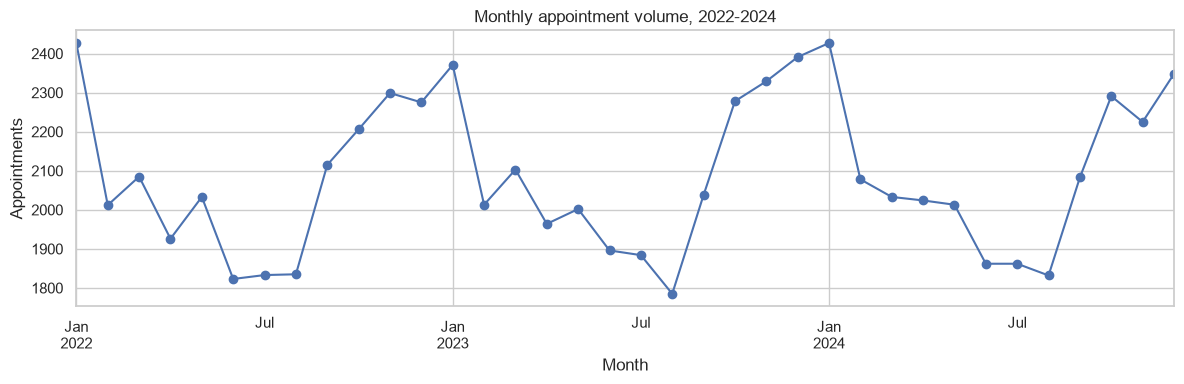

appointment_quarter,Q1,Q2,Q3,Q4
appointment_year,,,,
2022,6523,5782,5783,6780
2023,6487,5862,5707,6998
2024,6538,5899,5777,6864


In [10]:
# Monthly trend
monthly = df.groupby("year_month").size()

fig, ax = plt.subplots(figsize=(12, 4))
monthly.plot(ax=ax, marker="o")
ax.set_title("Monthly appointment volume, 2022-2024")
ax.set_xlabel("Month")
ax.set_ylabel("Appointments")
plt.tight_layout()
plt.savefig("images/6_1_monthly_trend.png")
plt.show()

# Quarterly view: years as rows, quarters as columns
quarterly = df.groupby(["appointment_year", "appointment_quarter"]).size().unstack()
quarterly

**Insight:** Volume is flat year on year (about 24,900 in 2022, 25,050 in 2023 and 25,080 in 2024), with a clear seasonal pattern: Q4 is the busiest quarter every year (6,780–6,998) and Q2–Q3 the quietest (about 5,700–5,900).

### 6.2 What is the split of outcomes across completed, no-show, cancelled, and scheduled appointments?

,appointments,share_%
appointment_status,,
Completed,55275,73.70
No-Show,11584,15.45
Cancelled,5793,7.72
Scheduled,2348,3.13


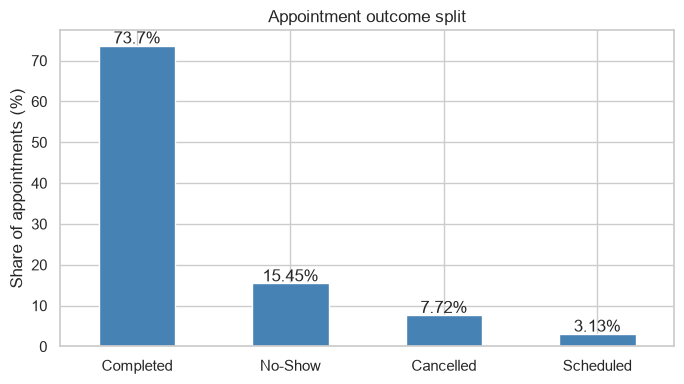

In [11]:
status = df["appointment_status"].value_counts()
status_pct = (df["appointment_status"].value_counts(normalize=True) * 100).round(2)
outcomes = pd.DataFrame({"appointments": status, "share_%": status_pct})
display(outcomes)

fig, ax = plt.subplots(figsize=(7, 4))
outcomes["share_%"].plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Appointment outcome split")
ax.set_xlabel("")
ax.set_ylabel("Share of appointments (%)")
for i, v in enumerate(outcomes["share_%"]):
    ax.text(i, v + 0.5, f"{v}%", ha="center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("images/6_2_outcome_split.png")
plt.show()

**Insight:** 73.7% of appointments were completed (55,275), 15.4% were no-shows (11,584), 7.7% were cancelled and 3.1% are still scheduled. Excluding scheduled appointments, the no-show rate is 15.94%.

### 6.3 Which booking channels drive the highest volume and how does the channel mix look?

,appointments,share_%
booking_channel,,
Apollo App,34042,45.39
Website,18545,24.73
Call Centre,11201,14.93
Walk-In,7501,10.00
Partner App,3711,4.95


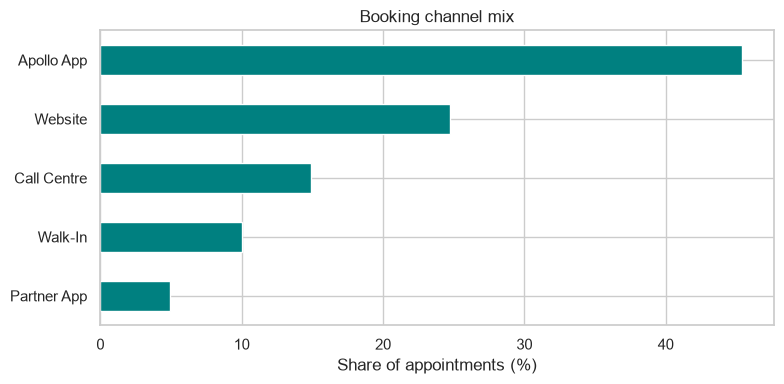

In [12]:
channel = df["booking_channel"].value_counts()
channel_pct = (df["booking_channel"].value_counts(normalize=True) * 100).round(2)
channels = pd.DataFrame({"appointments": channel, "share_%": channel_pct})
display(channels)

fig, ax = plt.subplots(figsize=(8, 4))
channels["share_%"].sort_values().plot(kind="barh", ax=ax, color="teal")
ax.set_title("Booking channel mix")
ax.set_xlabel("Share of appointments (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("images/6_3_channel_mix.png")
plt.show()

**Insight:** The Apollo App drives 45.4% of bookings (34,042), followed by the Website (24.7%) and the Call Centre (14.9%). Digital channels (App, Website and Partner App) together make up about 75% of volume.

## 7. No-Show Analysis

### 7.1 Which specialties and cities have the highest and lowest no-show rates?

,appointments,no_shows,no_show_rate_%
specialty,,,
Psychiatry,2900,711,24.52
Dermatology,7566,1608,21.25
ENT,5211,988,18.96
Endocrinology,2024,355,17.54
Ophthalmology,3103,503,16.21
General Physician,19654,3049,15.51
Pulmonology,2549,394,15.46
Orthopaedics,5419,810,14.95
Gastroenterology,2527,377,14.92


,appointments,no_shows,no_show_rate_%
city,,,
Lucknow,3001,516,17.19
Mumbai,9734,1659,17.04
Delhi,10404,1754,16.86
Bhopal,2001,336,16.79
Kolkata,5701,933,16.37
Kochi,2690,438,16.28
Ahmedabad,3468,561,16.18
Jaipur,2653,429,16.17
Hyderabad,7229,1160,16.05


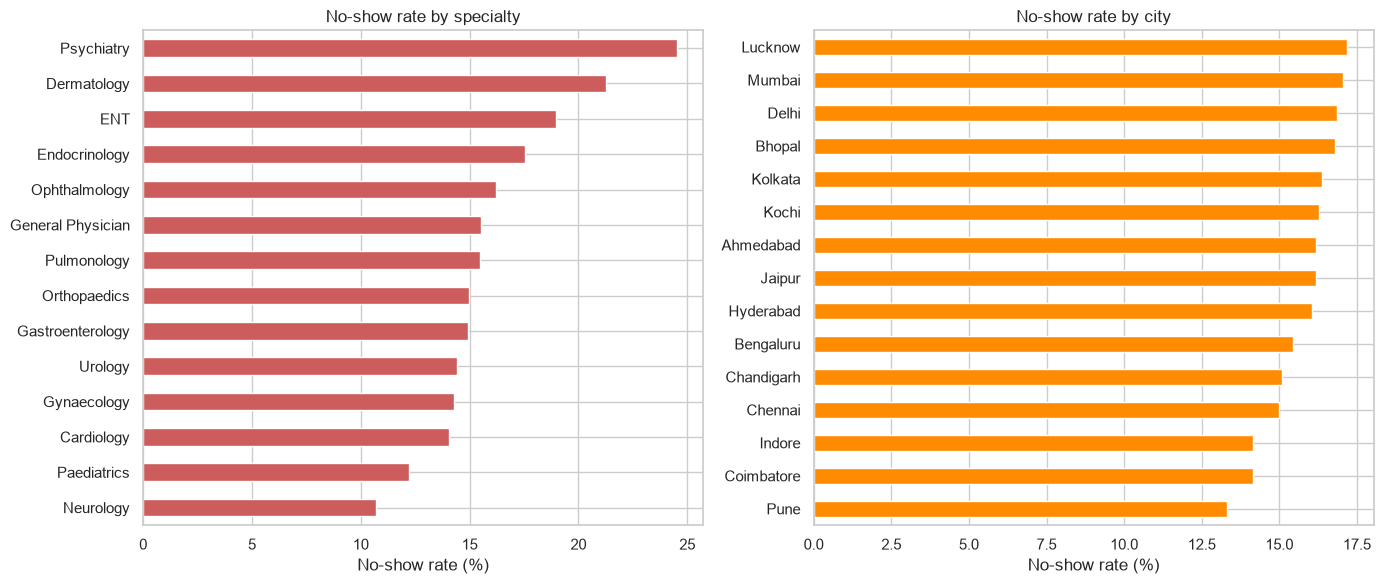

In [13]:
spec = no_show_rate(outcome_df, "specialty")
city = no_show_rate(outcome_df, "city")
display(spec)
display(city)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
spec["no_show_rate_%"].sort_values().plot(kind="barh", ax=axes[0], color="indianred")
axes[0].set_title("No-show rate by specialty")
axes[0].set_xlabel("No-show rate (%)")
axes[0].set_ylabel("")
city["no_show_rate_%"].sort_values().plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("No-show rate by city")
axes[1].set_xlabel("No-show rate (%)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig("images/7_1_noshow_specialty_city.png")
plt.show()

**Insight:** Psychiatry (24.5%) and Dermatology (21.3%) have the highest no-show rates, and Neurology (10.7%) and Paediatrics (12.2%) the lowest. Cities vary much less, from Lucknow (17.2%) to Pune (13.3%), so specialty matters more than city.

### 7.2 How does booking lead time affect the probability of a no-show?

,appointments,no_shows,no_show_rate_%
lead_bucket,,,
Same day,20180,3193,15.82
1-2 days,18680,2584,13.83
3-7 days,22692,3690,16.26
8-14 days,8758,1648,18.82
15-30 days,2342,469,20.03


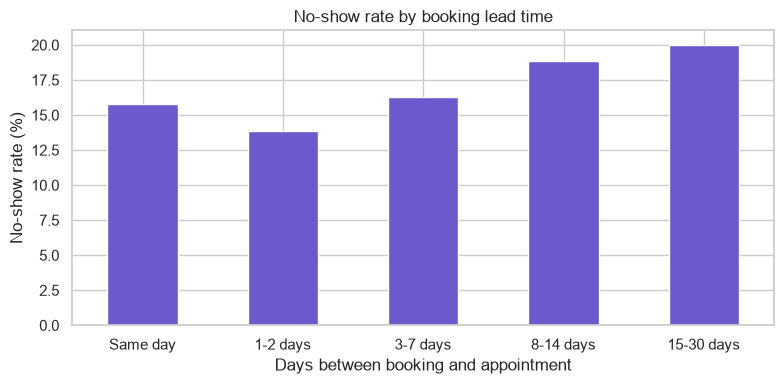

Correlation: 0.038


In [14]:
lead = no_show_rate(outcome_df, "lead_bucket").sort_index()
display(lead)

fig, ax = plt.subplots(figsize=(8, 4))
lead["no_show_rate_%"].plot(kind="bar", ax=ax, color="slateblue")
ax.set_title("No-show rate by booking lead time")
ax.set_xlabel("Days between booking and appointment")
ax.set_ylabel("No-show rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("images/7_2_noshow_lead_time.png")
plt.show()

print("Correlation:", round(outcome_df["booking_lead_days"].corr(outcome_df["no_show_flag"]), 3))

**Insight:** No-shows are lowest for bookings made 1–2 days ahead (13.8%) and rise steadily with lead time to 20.0% for bookings made 15–30 days ahead. The correlation is weak (0.04), but the trend across the groups is clear.

### 7.3 Do evening slots, weekends, and longer-lead bookings see higher dropout?

,appointments,no_shows,no_show_rate_%
time_of_day,,,
Morning,34868,4787,13.73
Afternoon,23231,4124,17.75
Evening,14553,2673,18.37


,appointments,no_shows,no_show_rate_%
is_weekend,,,
Weekend,20921,3908,18.68
Weekday,51731,7676,14.84


,appointments,no_shows,no_show_rate_%
lead_group,,,
Long lead (8+ days),11100,2117,19.07
Short lead (0-7 days),61552,9467,15.38


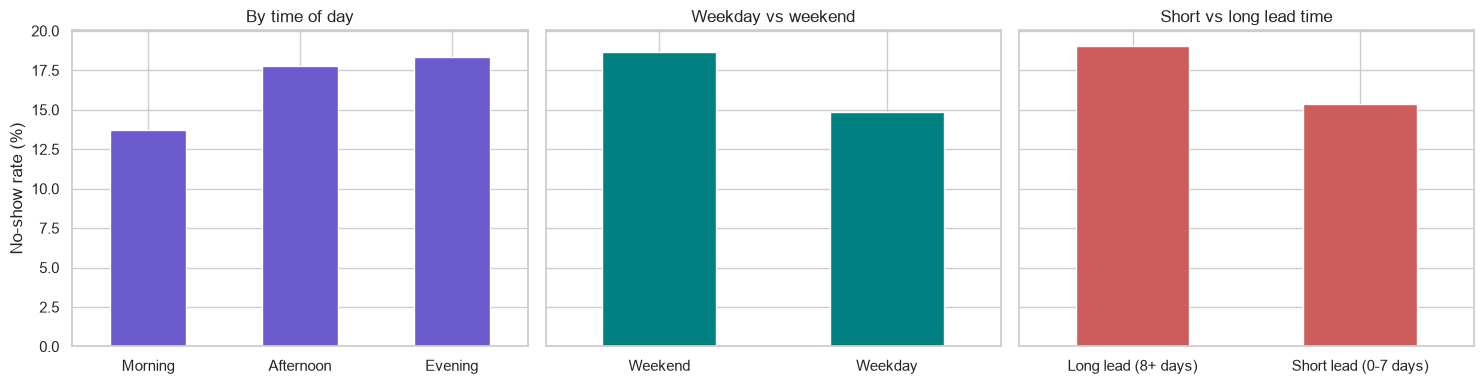

In [15]:
tod = no_show_rate(outcome_df, "time_of_day").reindex(["Morning", "Afternoon", "Evening"])
wkd = no_show_rate(outcome_df, "is_weekend")
outcome_df["lead_group"] = np.where(outcome_df["booking_lead_days"] > 7, "Long lead (8+ days)", "Short lead (0-7 days)")
lead_grp = no_show_rate(outcome_df, "lead_group")
display(tod)
display(wkd)
display(lead_grp)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
tod["no_show_rate_%"].plot(kind="bar", ax=axes[0], color="slateblue")
axes[0].set_title("By time of day")
wkd["no_show_rate_%"].plot(kind="bar", ax=axes[1], color="teal")
axes[1].set_title("Weekday vs weekend")
lead_grp["no_show_rate_%"].plot(kind="bar", ax=axes[2], color="indianred")
axes[2].set_title("Short vs long lead time")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("No-show rate (%)")
plt.tight_layout()
plt.savefig("images/7_3_slot_weekend_lead.png")
plt.show()

**Insight:** Yes, all three see higher dropout: evening slots 18.4% vs 13.7% in the morning, weekends 18.7% vs 14.8% on weekdays, and bookings made 8+ days ahead 19.1% vs 15.4% for shorter lead times.

### 7.4 Which appointment types and booking channels carry the most no-show risk?

,appointments,no_shows,no_show_rate_%
appointment_type,,,
Home Visit,9742,2557,26.25
Video Consult,15349,3232,21.06
In-Clinic,47561,5795,12.18


,appointments,no_shows,no_show_rate_%
booking_channel,,,
Walk-In,7281,1520,20.88
Partner App,3594,651,18.11
Website,17964,3090,17.20
Call Centre,10855,1650,15.20
Apollo App,32958,4673,14.18


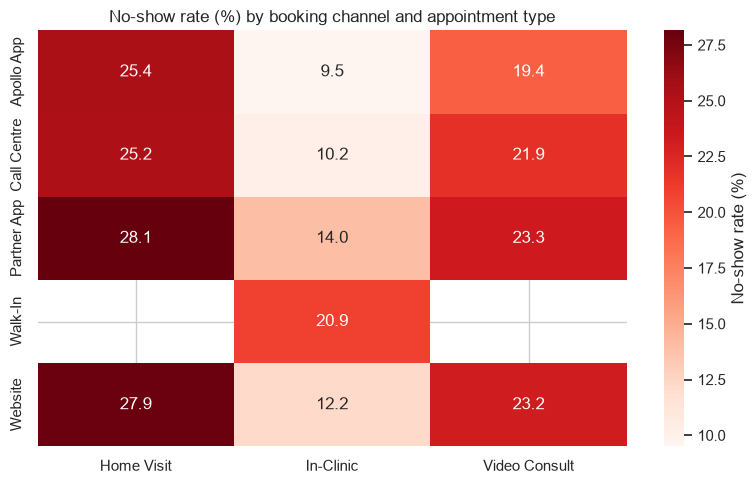

In [16]:
appt_type = no_show_rate(outcome_df, "appointment_type")
channel_ns = no_show_rate(outcome_df, "booking_channel")
display(appt_type)
display(channel_ns)

# No-show rate for every channel x type combination
combo = outcome_df.pivot_table(index="booking_channel", columns="appointment_type",
                               values="no_show_flag", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(combo, annot=True, fmt=".1f", cmap="Reds", ax=ax,
            cbar_kws={"label": "No-show rate (%)"})
ax.set_title("No-show rate (%) by booking channel and appointment type")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("images/7_4_type_channel_heatmap.png")
plt.show()

**Insight:** Home Visits (26.3%) and Video Consults (21.1%) carry far more risk than In-Clinic visits (12.2%). Walk-In is the riskiest channel (20.9%) and the Apollo App the safest (14.2%); the worst combination is Partner App + Home Visit (28.1%).

## 8. Reminder and Engagement Effectiveness

### 8.1 How much does reminder type reduce no-show rates compared to no-reminder patients?

,appointments,no_shows,no_show_rate_%,reduction_vs_no_reminder_pts,relative_reduction_%
reminder_type,,,,,
No Reminder,10977,3311,30.16,0.00,0.0
SMS Only,14527,2363,16.27,13.89,46.1
SMS + WhatsApp,25273,3414,13.51,16.65,55.2
SMS + WhatsApp + Call,21875,2496,11.41,18.75,62.2


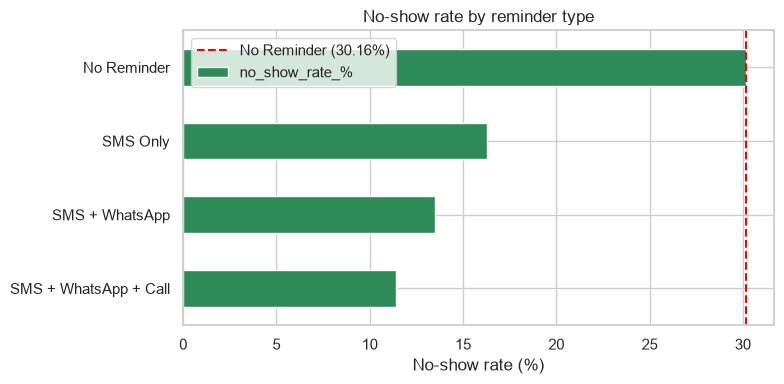

In [17]:
reminder = no_show_rate(outcome_df, "reminder_type")
baseline = reminder.loc["No Reminder", "no_show_rate_%"]
reminder["reduction_vs_no_reminder_pts"] = (baseline - reminder["no_show_rate_%"]).round(2)
reminder["relative_reduction_%"] = ((baseline - reminder["no_show_rate_%"]) / baseline * 100).round(1)
display(reminder)

fig, ax = plt.subplots(figsize=(8, 4))
reminder["no_show_rate_%"].sort_values().plot(kind="barh", ax=ax, color="seagreen")
ax.axvline(baseline, color="red", linestyle="--", label=f"No Reminder ({baseline}%)")
ax.set_title("No-show rate by reminder type")
ax.set_xlabel("No-show rate (%)")
ax.set_ylabel("")
ax.legend()
plt.tight_layout()
plt.savefig("images/8_1_reminder_effect.png")
plt.show()

**Insight:** Patients with no reminder miss 30.2% of appointments. SMS alone cuts this to 16.3% (46% lower), SMS + WhatsApp to 13.5% (55% lower), and the full SMS + WhatsApp + Call bundle to 11.4% (62% lower).

### 8.2 Does prior no-show history predict future no-show behaviour?

,appointments,no_shows,no_show_rate_%
prior_no_show_group,,,
0 prior,63014,9549,15.15
1 prior,8502,1723,20.27
2+ prior,1136,312,27.46


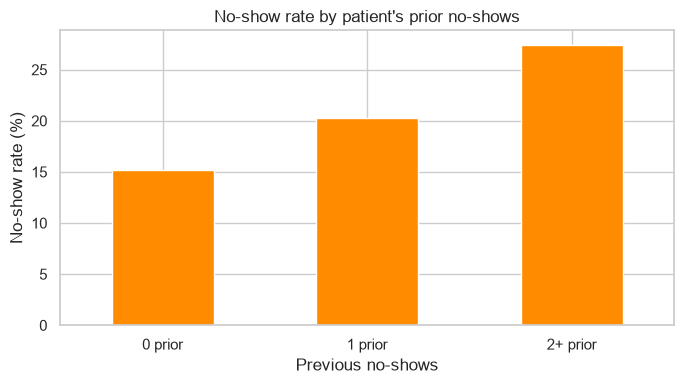

Correlation: 0.06


In [18]:
outcome_df["prior_no_show_group"] = pd.cut(outcome_df["patient_prior_no_shows"],
                                           bins=[-1, 0, 1, 100],
                                           labels=["0 prior", "1 prior", "2+ prior"])
prior = no_show_rate(outcome_df, "prior_no_show_group").sort_index()
display(prior)

fig, ax = plt.subplots(figsize=(7, 4))
prior["no_show_rate_%"].plot(kind="bar", ax=ax, color="darkorange")
ax.set_title("No-show rate by patient's prior no-shows")
ax.set_xlabel("Previous no-shows")
ax.set_ylabel("No-show rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("images/8_2_prior_no_shows.png")
plt.show()

print("Correlation:", round(outcome_df["patient_prior_no_shows"].corr(outcome_df["no_show_flag"]), 3))

**Insight:** Yes. Patients with no prior no-shows miss 15.2% of appointments, compared with 20.3% for those with 1 prior no-show and 27.5% for those with 2 or more.

### 8.3 Do Apollo members and repeat patients show better attendance than non-members and first-time patients?

,appointments,no_shows,no_show_rate_%
membership_type,,,
None,56428,9530,16.89
Apollo Silver,8057,1021,12.67
Apollo Gold,8167,1033,12.65


,appointments,no_shows,no_show_rate_%
repeat_visit,,,
No,9182,6132,66.78
Yes,63470,5452,8.59


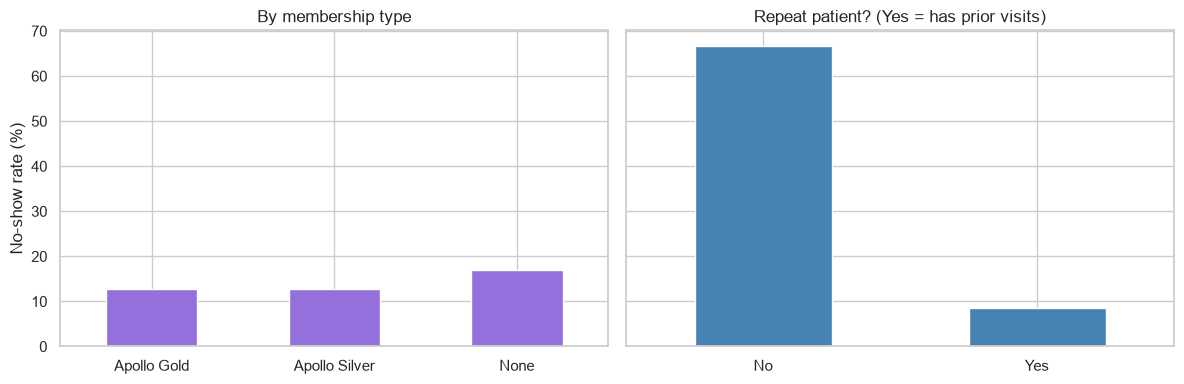

In [19]:
member = no_show_rate(outcome_df, "membership_type")
repeat = no_show_rate(outcome_df, "repeat_visit")
display(member)
display(repeat)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
member["no_show_rate_%"].sort_values().plot(kind="bar", ax=axes[0], color="mediumpurple")
axes[0].set_title("By membership type")
axes[0].set_ylabel("No-show rate (%)")
repeat["no_show_rate_%"].plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Repeat patient? (Yes = has prior visits)")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("images/8_3_member_repeat.png")
plt.show()

**Insight:** Apollo members (Gold and Silver) miss 12.7% of appointments vs 16.9% for non-members. First-time patients miss 66.8% vs 8.6% for repeat patients, though this gap is partly due to how the column is defined: a patient who never shows up stays "first-time".

## 9. Patient and Demographic Segmentation

### 9.1 How do age group, gender, and chronic condition status influence no-show likelihood?

,appointments,no_shows,no_show_rate_%
age_group,,,
Child (0-12),11745,1590,13.54
Teen (13-18),6379,939,14.72
Young Adult (19-30),10017,1797,17.94
Adult (31-45),15133,2731,18.05
Middle-aged (46-60),14862,2491,16.76
Senior (60+),14516,2036,14.03


,appointments,no_shows,no_show_rate_%
patient_gender,,,
Female,37589,6029,16.04
Male,35063,5555,15.84


,appointments,no_shows,no_show_rate_%
patient_chronic_condition,,,
Asthma,9098,1520,16.71
Heart Disease,9155,1494,16.32
None,27144,4314,15.89
Diabetes,9010,1421,15.77
Hypertension,9100,1417,15.57
Hypothyroidism,9145,1418,15.51


,appointments,no_shows,no_show_rate_%
has_chronic,,,
Has chronic condition,45508,7270,15.98
No chronic condition,27144,4314,15.89


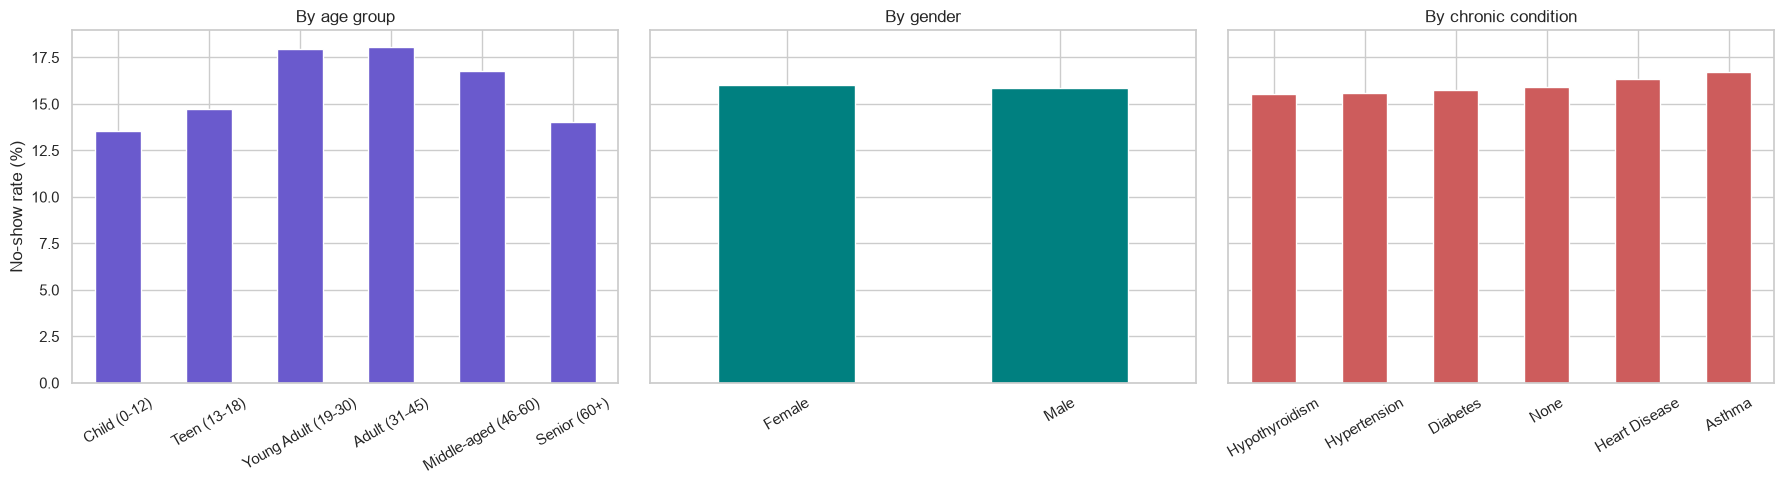

In [20]:
age_order = ["Child (0-12)", "Teen (13-18)", "Young Adult (19-30)",
             "Adult (31-45)", "Middle-aged (46-60)", "Senior (60+)"]
age = no_show_rate(outcome_df, "age_group").reindex(age_order)
gender = no_show_rate(outcome_df, "patient_gender")
chronic = no_show_rate(outcome_df, "patient_chronic_condition")
outcome_df["has_chronic"] = np.where(outcome_df["patient_chronic_condition"] == "None",
                                     "No chronic condition", "Has chronic condition")
chronic_flag = no_show_rate(outcome_df, "has_chronic")
display(age)
display(gender)
display(chronic)
display(chronic_flag)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
age["no_show_rate_%"].plot(kind="bar", ax=axes[0], color="slateblue")
axes[0].set_title("By age group")
axes[0].set_ylabel("No-show rate (%)")
gender["no_show_rate_%"].plot(kind="bar", ax=axes[1], color="teal")
axes[1].set_title("By gender")
chronic["no_show_rate_%"].sort_values().plot(kind="bar", ax=axes[2], color="indianred")
axes[2].set_title("By chronic condition")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("images/9_1_age_gender_chronic.png")
plt.show()

**Insight:** Young adults (17.9%) and adults aged 31–45 (18.1%) miss the most, while children (13.5%) and seniors (14.0%) miss the least. Gender (16.0% vs 15.8%) and chronic condition (16.0% vs 15.9%) make almost no difference.

### 9.2 Which visit reasons are most common and are some associated with higher dropout?

,appointments,no_shows,no_show_rate_%,total_bookings
visit_reason,,,,
Skin Issue,2782,467,16.79,2862
Joint Pain,6469,1082,16.73,6664
Cardiac Concern,2639,430,16.29,2708
Mental Health,2733,445,16.28,2830
Digestive Problem,7984,1297,16.24,8245
Injury,5884,949,16.13,6087
Fever & Infection,6808,1095,16.08,7041
Respiratory Issue,6383,1020,15.98,6590
Women's Health,2362,377,15.96,2449


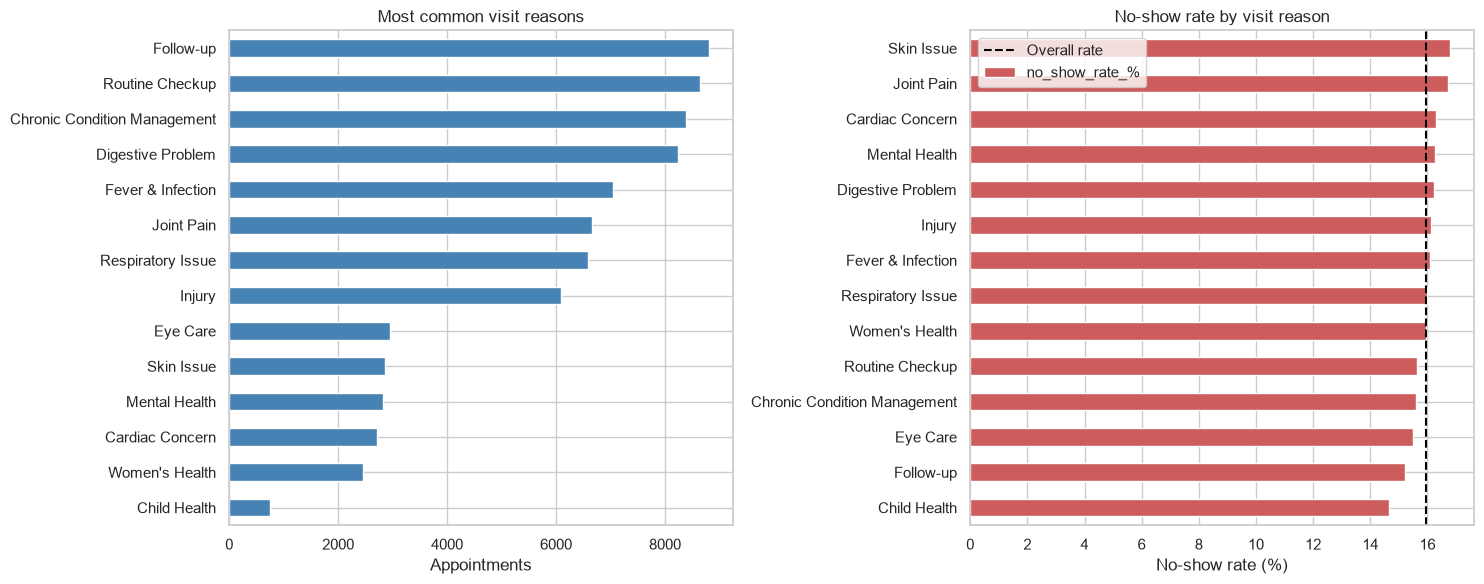

In [21]:
reason_counts = df["visit_reason"].value_counts()
reason_ns = no_show_rate(outcome_df, "visit_reason")
reasons = reason_ns.join(reason_counts.rename("total_bookings"))
display(reasons)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
reason_counts.sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Most common visit reasons")
axes[0].set_xlabel("Appointments")
axes[0].set_ylabel("")
reason_ns["no_show_rate_%"].sort_values().plot(kind="barh", ax=axes[1], color="indianred")
axes[1].axvline(outcome_df["no_show_flag"].mean() * 100, color="black", linestyle="--", label="Overall rate")
axes[1].set_title("No-show rate by visit reason")
axes[1].set_xlabel("No-show rate (%)")
axes[1].set_ylabel("")
axes[1].legend()
plt.tight_layout()
plt.savefig("images/9_2_visit_reasons.png")
plt.show()

**Insight:** The most common reasons are Follow-up (8,807), Routine Checkup (8,637) and Chronic Condition Management (8,380). No-show rates are very similar across reasons (14.6% for Child Health to 16.8% for Skin Issue), so visit reason is not a strong predictor of dropout.

### 9.3 What does the patient age distribution look like within Paediatrics, Gynaecology, and Psychiatry?

,count,mean,std,min,25%,50%,75%,max
specialty,,,,,,,,
Gynaecology,4113.0,41.7,21.7,1.0,25.0,42.0,59.0,85.0
Paediatrics,6382.0,9.3,5.0,1.0,5.0,9.0,14.0,18.0
Psychiatry,2989.0,42.0,21.7,1.0,25.0,42.0,59.0,85.0


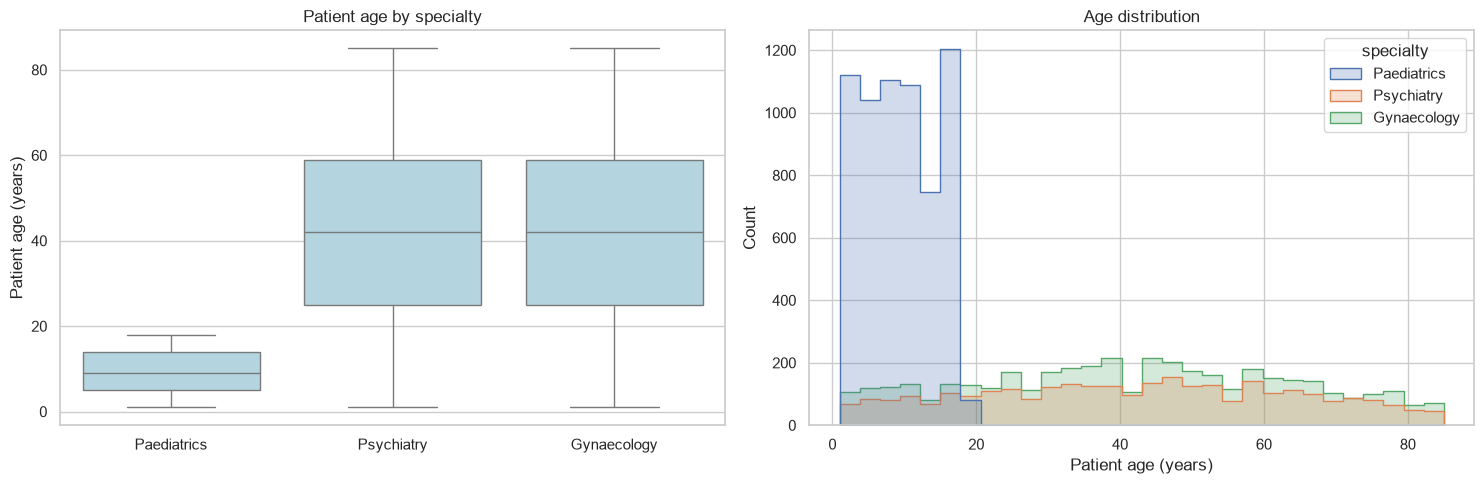

In [22]:
focus = df[df["specialty"].isin(["Paediatrics", "Gynaecology", "Psychiatry"])]
display(focus.groupby("specialty")["patient_age"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=focus, x="specialty", y="patient_age", ax=axes[0], color="lightblue")
axes[0].set_title("Patient age by specialty")
axes[0].set_xlabel("")
axes[0].set_ylabel("Patient age (years)")
sns.histplot(data=focus, x="patient_age", hue="specialty", bins=30, element="step", ax=axes[1])
axes[1].set_title("Age distribution")
axes[1].set_xlabel("Patient age (years)")
plt.tight_layout()
plt.savefig("images/9_3_age_by_specialty.png")
plt.show()

**Insight:** Paediatrics patients are 1–18 years old (median 9), as expected. Gynaecology and Psychiatry both cover ages 1–85 with a median of 42; Gynaecology also includes 92 male patients, which looks like a data quality quirk.

## 10. Financial Performance (Completed rows only)

### 10.1 How much revenue is being lost to no-shows?

No-show appointments:           11,584
Gross loss (listed fees):       Rs 19,725,460
Completed fee ratio:            96.0%
Estimated loss after discounts: Rs 18,944,582
Billed on completed visits:     Rs 86,270,029
Loss as % of billed revenue:    22.0%


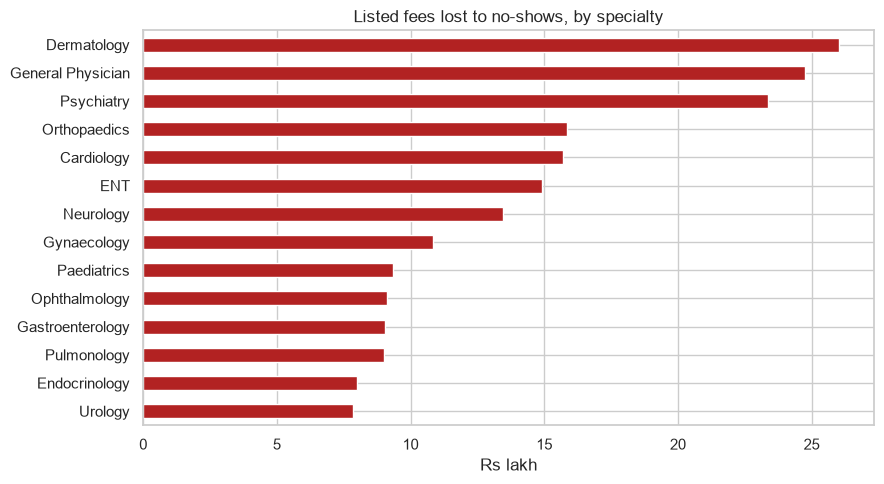

In [23]:
no_show_rows = df[df["appointment_status"] == "No-Show"]

# 1) Gross loss: the listed fee of every missed appointment
gross_loss = no_show_rows["consultation_fee"].sum()

# 2) Realistic loss: completed visits only collect part of the listed fee
#    (because of discounts), so apply the same ratio to the missed fees
fee_ratio = completed_df["actual_fee_charged"].sum() / completed_df["consultation_fee"].sum()
billed_loss = gross_loss * fee_ratio

collected = completed_df["actual_fee_charged"].sum()
print(f"No-show appointments:           {len(no_show_rows):,}")
print(f"Gross loss (listed fees):       Rs {gross_loss:,.0f}")
print(f"Completed fee ratio:            {fee_ratio:.1%}")
print(f"Estimated loss after discounts: Rs {billed_loss:,.0f}")
print(f"Billed on completed visits:     Rs {collected:,.0f}")
print(f"Loss as % of billed revenue:    {billed_loss / collected:.1%}")

loss_by_spec = (no_show_rows.groupby("specialty")["consultation_fee"].sum() / 1e5).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
loss_by_spec.plot(kind="barh", ax=ax, color="firebrick")
ax.set_title("Listed fees lost to no-shows, by specialty")
ax.set_xlabel("Rs lakh")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("images/10_1_revenue_lost.png")
plt.show()

**Insight:** The 11,584 no-shows add up to ₹1.97 crore in listed fees, or about ₹1.89 crore after the typical 4% discount. That equals 22% of the ₹8.63 crore billed on completed visits; Dermatology (₹26.0 lakh) and General Physician (₹24.8 lakh) lose the most.

### 10.2 How does average revenue vary across specialties and appointment types?

,appointments,avg_fee_billed,avg_revenue
specialty,,,
Psychiatry,1958,3090.0,2640.0
Neurology,3899,2416.0,2076.0
Urology,1729,2325.0,1989.0
Cardiology,3507,2276.0,1941.0
Gastroenterology,1972,2200.0,1897.0
Endocrinology,1504,2116.0,1813.0
Pulmonology,1961,2102.0,1803.0
Orthopaedics,4189,1808.0,1547.0
Gynaecology,3134,1753.0,1500.0


,appointments,avg_fee_billed,avg_revenue
appointment_type,,,
Home Visit,6436,2280.0,1960.0
In-Clinic,37938,1521.0,1300.0
Video Consult,10901,1273.0,1098.0


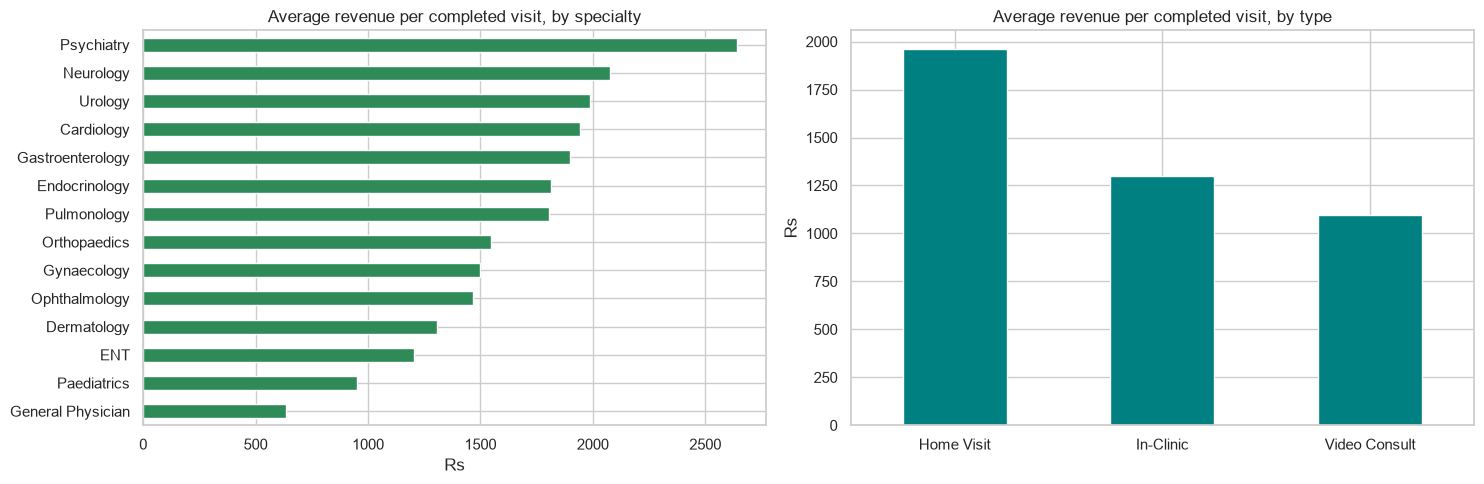

In [24]:
rev_spec = (completed_df.groupby("specialty")
            .agg(appointments=("revenue_realized", "size"),
                 avg_fee_billed=("actual_fee_charged", "mean"),
                 avg_revenue=("revenue_realized", "mean"))
            .round(0).sort_values("avg_revenue", ascending=False))
rev_type = (completed_df.groupby("appointment_type")
            .agg(appointments=("revenue_realized", "size"),
                 avg_fee_billed=("actual_fee_charged", "mean"),
                 avg_revenue=("revenue_realized", "mean"))
            .round(0).sort_values("avg_revenue", ascending=False))
display(rev_spec)
display(rev_type)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
rev_spec["avg_revenue"].sort_values().plot(kind="barh", ax=axes[0], color="seagreen")
axes[0].set_title("Average revenue per completed visit, by specialty")
axes[0].set_xlabel("Rs")
axes[0].set_ylabel("")
rev_type["avg_revenue"].plot(kind="bar", ax=axes[1], color="teal")
axes[1].set_title("Average revenue per completed visit, by type")
axes[1].set_ylabel("Rs")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("images/10_2_avg_revenue.png")
plt.show()

**Insight:** Psychiatry earns the most per visit (₹2,640), followed by Neurology (₹2,076), while General Physician earns the least (₹633) but has the most visits (14,981). Home Visits earn ₹1,960 per visit vs ₹1,300 for In-Clinic and ₹1,098 for Video Consults.

### 10.3 Which cities generate the most revenue and what is the payment mode mix?

city
Bengaluru     99.9
Delhi         99.6
Mumbai        89.9
Hyderabad     75.0
Chennai       71.9
Kolkata       65.4
Pune          47.3
Ahmedabad     39.6
Lucknow       31.8
Indore        22.2
Chandigarh    22.2
Jaipur        22.0
Coimbatore    17.9
Kochi         17.3
Bhopal        16.8
Name: revenue_Rs_lakh, dtype: float64

payment_mode
Insurance      21.1
Debit Card     13.3
Net Banking    13.3
Apollo Pay     13.3
UPI            13.1
Credit Card    13.0
Cash           12.9
Name: share_%, dtype: float64

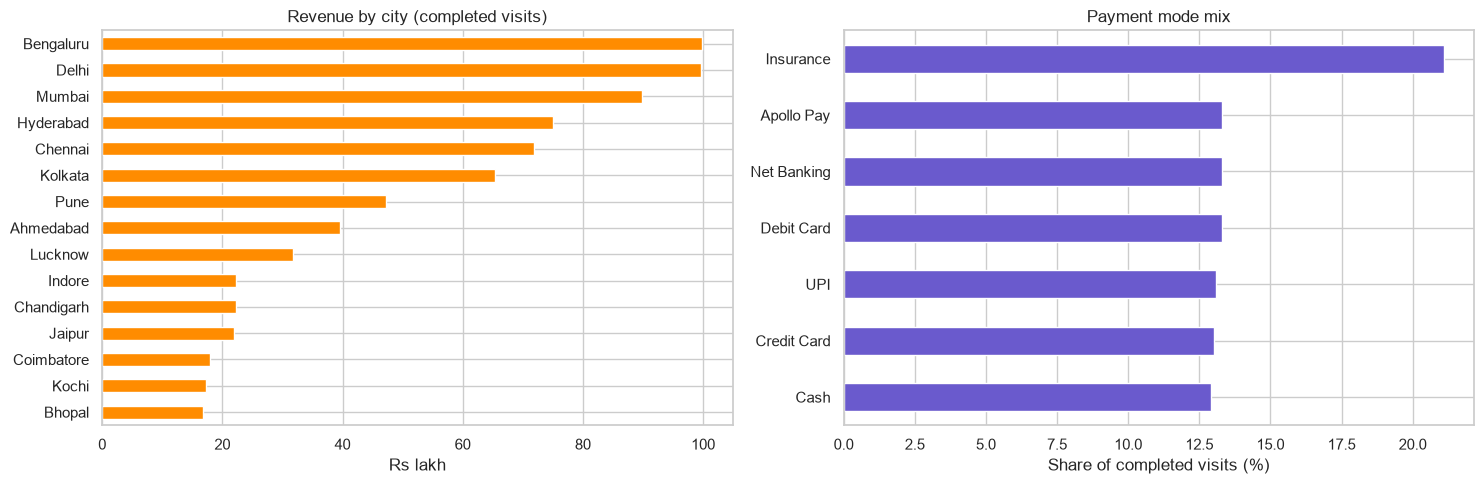

In [25]:
city_rev = (completed_df.groupby("city")["revenue_realized"].sum() / 1e5).sort_values(ascending=False).round(1)
pay_mix = (completed_df["payment_mode"].value_counts(normalize=True) * 100).round(1)
display(city_rev.rename("revenue_Rs_lakh"))
display(pay_mix.rename("share_%"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
city_rev.sort_values().plot(kind="barh", ax=axes[0], color="darkorange")
axes[0].set_title("Revenue by city (completed visits)")
axes[0].set_xlabel("Rs lakh")
axes[0].set_ylabel("")
pay_mix.sort_values().plot(kind="barh", ax=axes[1], color="slateblue")
axes[1].set_title("Payment mode mix")
axes[1].set_xlabel("Share of completed visits (%)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig("images/10_3_city_revenue_payment.png")
plt.show()

**Insight:** Bengaluru (₹99.9 lakh), Delhi (₹99.6 lakh) and Mumbai (₹89.9 lakh) bring in 39% of revenue. Insurance is the largest payment mode (21.1% of completed visits); the other six modes are spread evenly at about 13% each.

### 10.4 How does insurance coverage affect what patients pay out of pocket?

,visits,avg_fee_billed,avg_insurer_paid,avg_out_of_pocket,patient_share_%
insurance_coverage,,,,,
No,37523,1563.0,0.0,1563.0,100.0
Yes,17752,1556.0,697.0,859.0,55.2


insurance_provider
Niva Bupa              844.0
HDFC ERGO              856.0
Bajaj Allianz          857.0
Star Health            869.0
New India Assurance    871.0
Name: avg_out_of_pocket, dtype: float64

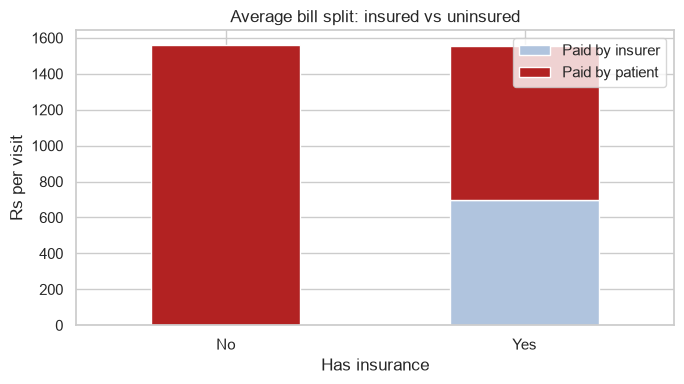

In [26]:
ins = (completed_df.groupby("insurance_coverage")
       .agg(visits=("patient_out_of_pocket", "size"),
            avg_fee_billed=("actual_fee_charged", "mean"),
            avg_insurer_paid=("insurance_covered_amount", "mean"),
            avg_out_of_pocket=("patient_out_of_pocket", "mean"))
       .round(0))
ins["patient_share_%"] = (ins["avg_out_of_pocket"] / ins["avg_fee_billed"] * 100).round(1)
display(ins)

by_provider = (completed_df[completed_df["insurance_coverage"] == "Yes"]
               .groupby("insurance_provider")["patient_out_of_pocket"].mean()
               .round(0).sort_values())
display(by_provider.rename("avg_out_of_pocket"))

fig, ax = plt.subplots(figsize=(7, 4))
ins[["avg_insurer_paid", "avg_out_of_pocket"]].plot(kind="bar", stacked=True, ax=ax,
                                                    color=["lightsteelblue", "firebrick"])
ax.set_title("Average bill split: insured vs uninsured")
ax.set_xlabel("Has insurance")
ax.set_ylabel("Rs per visit")
ax.legend(["Paid by insurer", "Paid by patient"])
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("images/10_4_insurance_out_of_pocket.png")
plt.show()

**Insight:** Insured and uninsured patients get similar bills (about ₹1,560 per visit), but insured patients pay only ₹859 out of pocket (55%) because the insurer covers about ₹697. Uninsured patients pay the full ₹1,563.

## 11. Doctor Utilisation and Service Quality (Completed rows only)

### 11.1 Which specialties have the highest and lowest doctor utilisation rates?

,mean,median
specialty,,
Gastroenterology,77.3,77.8
Endocrinology,77.1,77.7
Cardiology,76.8,76.9
Gynaecology,76.8,77.1
Paediatrics,76.7,76.5
General Physician,76.6,76.4
Neurology,76.6,76.6
Dermatology,76.4,76.3
Urology,76.4,77.0


Overall average utilisation: 76.6 %


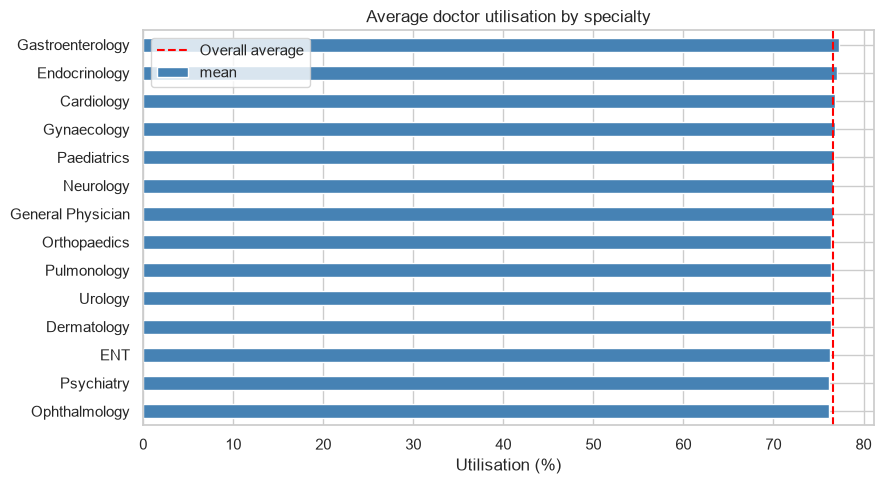

In [27]:
util = (completed_df.groupby("specialty")["doctor_utilization_pct"]
        .agg(["mean", "median"]).round(1).sort_values("mean", ascending=False))
display(util)
print("Overall average utilisation:", round(completed_df["doctor_utilization_pct"].mean(), 1), "%")

fig, ax = plt.subplots(figsize=(9, 5))
util["mean"].sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.axvline(completed_df["doctor_utilization_pct"].mean(), color="red", linestyle="--", label="Overall average")
ax.set_title("Average doctor utilisation by specialty")
ax.set_xlabel("Utilisation (%)")
ax.set_ylabel("")
ax.legend()
plt.tight_layout()
plt.savefig("images/11_1_utilisation.png")
plt.show()

**Insight:** Utilisation is almost the same across specialties, averaging 76.6%. The highest is Gastroenterology (77.3%) and the lowest Ophthalmology and Psychiatry (76.2%), a spread of only about 1 percentage point.

### 11.2 How long are patients waiting and does it vary by specialty or time of day?

count    55275.0
mean        11.5
std         12.1
min          0.0
25%          3.0
50%          8.0
75%         16.0
max         90.0
Name: wait_time_minutes, dtype: float64


specialty
Ophthalmology        12.0
Urology              11.9
Dermatology          11.8
Orthopaedics         11.7
Neurology            11.6
Cardiology           11.6
Gynaecology          11.6
Endocrinology        11.5
General Physician    11.5
Gastroenterology     11.4
Pulmonology          11.4
ENT                  11.3
Psychiatry           11.3
Paediatrics          11.2
Name: wait_time_minutes, dtype: float64

time_of_day
Morning      11.5
Afternoon    11.6
Evening      11.6
Name: wait_time_minutes, dtype: float64

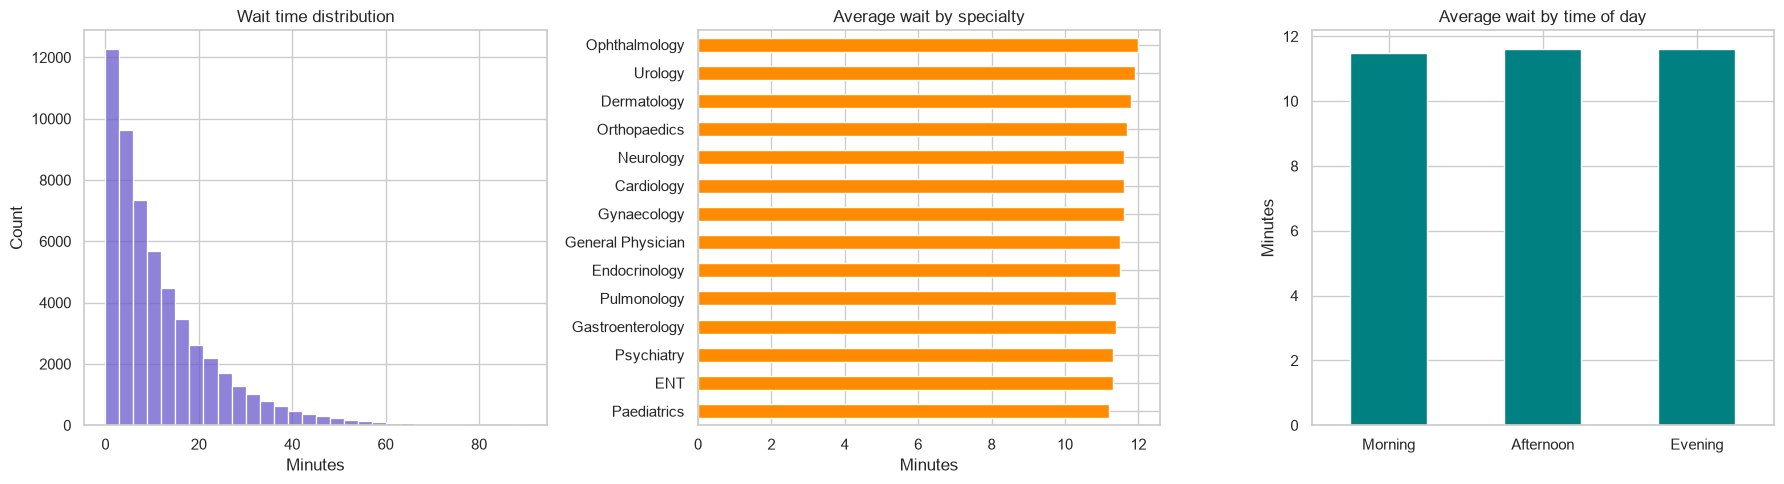

In [28]:
print(completed_df["wait_time_minutes"].describe().round(1))

wait_spec = completed_df.groupby("specialty")["wait_time_minutes"].mean().round(1).sort_values(ascending=False)
wait_tod = (completed_df.groupby("time_of_day")["wait_time_minutes"].mean().round(1)
            .reindex(["Morning", "Afternoon", "Evening"]))
display(wait_spec)
display(wait_tod)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(completed_df["wait_time_minutes"], bins=30, ax=axes[0], color="slateblue")
axes[0].set_title("Wait time distribution")
axes[0].set_xlabel("Minutes")
wait_spec.sort_values().plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("Average wait by specialty")
axes[1].set_xlabel("Minutes")
axes[1].set_ylabel("")
wait_tod.plot(kind="bar", ax=axes[2], color="teal")
axes[2].set_title("Average wait by time of day")
axes[2].set_ylabel("Minutes")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("images/11_2_wait_time.png")
plt.show()

**Insight:** Patients wait 11.5 minutes on average and half wait 8 minutes or less, with a few waits up to 90 minutes. Wait time barely changes by specialty (11.2–12.0 min) or time of day (11.5–11.6 min).

### 11.3 Is there a relationship between consultation duration and patient satisfaction?

Correlation (duration vs satisfaction): -0.004


,visits,avg_satisfaction
duration_band,,
5-10 min,11146,4.07
11-15 min,11864,4.07
16-20 min,11434,4.06
21-30 min,14891,4.07
31+ min,5940,4.07


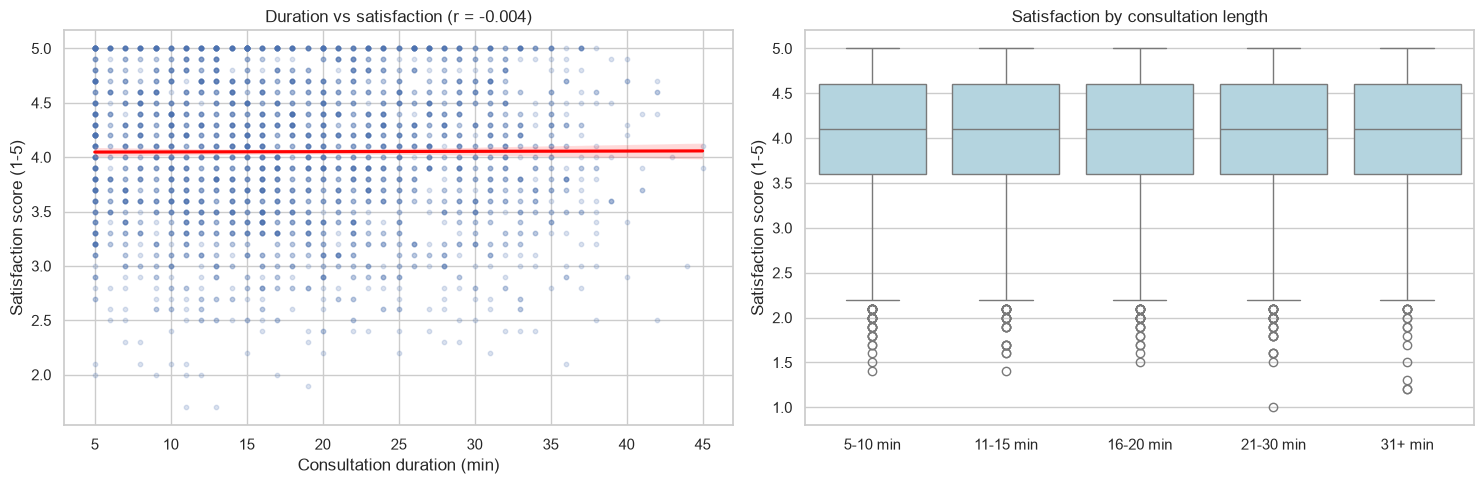

In [29]:
corr = completed_df["consultation_duration_min"].corr(completed_df["patient_satisfaction_score"])
print("Correlation (duration vs satisfaction):", round(corr, 3))

completed_df["duration_band"] = pd.cut(completed_df["consultation_duration_min"],
                                       bins=[0, 10, 15, 20, 30, 60],
                                       labels=["5-10 min", "11-15 min", "16-20 min", "21-30 min", "31+ min"])
by_band = (completed_df.groupby("duration_band", observed=True)["patient_satisfaction_score"]
           .agg(visits="size", avg_satisfaction="mean").round(2))
display(by_band)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sample = completed_df.sample(3000, random_state=42)   # 3,000 points so the scatter is readable
sns.regplot(data=sample, x="consultation_duration_min", y="patient_satisfaction_score",
            ax=axes[0], scatter_kws={"alpha": 0.2, "s": 10}, line_kws={"color": "red"})
axes[0].set_title(f"Duration vs satisfaction (r = {corr:.3f})")
axes[0].set_xlabel("Consultation duration (min)")
axes[0].set_ylabel("Satisfaction score (1-5)")
sns.boxplot(data=completed_df, x="duration_band", y="patient_satisfaction_score",
            ax=axes[1], color="lightblue")
axes[1].set_title("Satisfaction by consultation length")
axes[1].set_xlabel("")
axes[1].set_ylabel("Satisfaction score (1-5)")
plt.tight_layout()
plt.savefig("images/11_3_duration_satisfaction.png")
plt.show()

**Insight:** There is no relationship: the correlation is -0.004, and average satisfaction stays at 4.06–4.07 whether a consultation lasts 5–10 minutes or more than 30.

### 11.4 How does doctor experience relate to the fee charged?

Correlation (experience vs listed fee), all doctors: 0.278


specialty
Psychiatry           0.98
Gynaecology          0.97
Pulmonology          0.97
Orthopaedics         0.95
Gastroenterology     0.95
ENT                  0.93
Paediatrics          0.93
Ophthalmology        0.93
Urology              0.93
General Physician    0.92
Cardiology           0.91
Dermatology          0.91
Neurology            0.90
Endocrinology        0.86
Name: corr_within_specialty, dtype: float64

,count,mean
exp_band,,
2-5 yrs,51,1320.0
6-10 yrs,60,1445.0
11-15 yrs,46,1515.0
16-20 yrs,60,1530.0
20+ yrs,103,1850.0


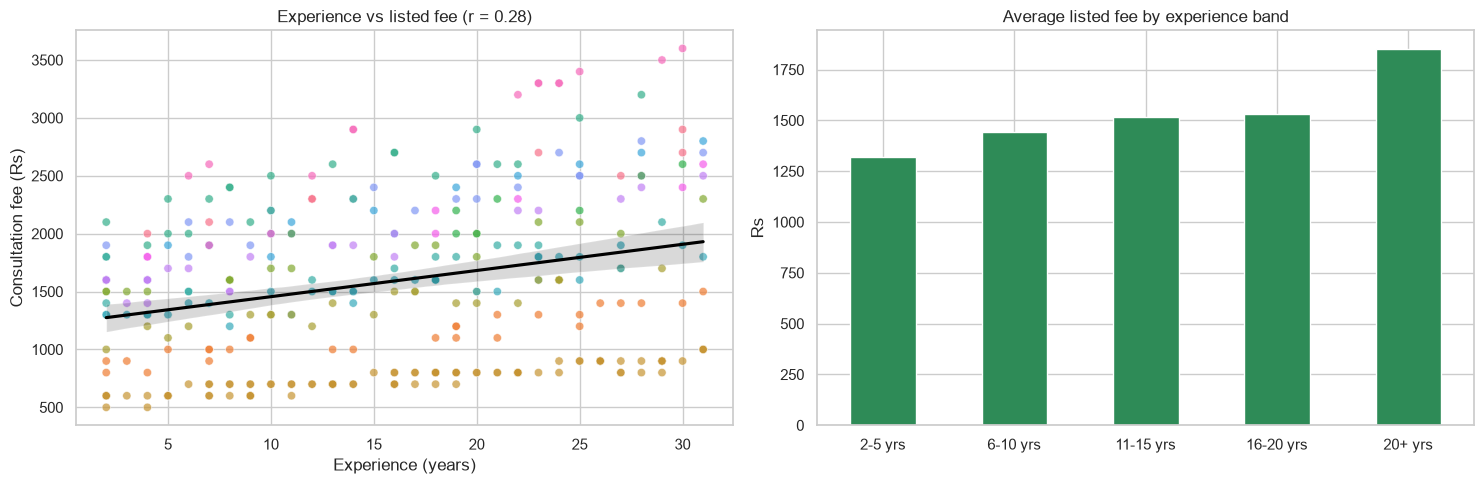

In [30]:
# Doctor level: one row per doctor, from the doctors table
corr_all = doctors["experience_years"].corr(doctors["consultation_fee"])
print("Correlation (experience vs listed fee), all doctors:", round(corr_all, 3))

# Fee depends a lot on specialty, so also check the relationship WITHIN each specialty
within = (doctors.groupby("specialty")
          .apply(lambda g: g["experience_years"].corr(g["consultation_fee"]), include_groups=False)
          .round(2).sort_values(ascending=False))
display(within.rename("corr_within_specialty"))

# Average fee by experience band
doctors["exp_band"] = pd.cut(doctors["experience_years"], bins=[0, 5, 10, 15, 20, 40],
                             labels=["2-5 yrs", "6-10 yrs", "11-15 yrs", "16-20 yrs", "20+ yrs"])
fee_by_exp = doctors.groupby("exp_band", observed=True)["consultation_fee"].agg(["count", "mean"]).round(0)
display(fee_by_exp)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=doctors, x="experience_years", y="consultation_fee", hue="specialty",
                ax=axes[0], legend=False, alpha=0.7)
sns.regplot(data=doctors, x="experience_years", y="consultation_fee", scatter=False,
            ax=axes[0], color="black")
axes[0].set_title(f"Experience vs listed fee (r = {corr_all:.2f})")
axes[0].set_xlabel("Experience (years)")
axes[0].set_ylabel("Consultation fee (Rs)")
fee_by_exp["mean"].plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Average listed fee by experience band")
axes[1].set_xlabel("")
axes[1].set_ylabel("Rs")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("images/11_4_experience_fee.png")
plt.show()

**Insight:** Across all doctors, experience is only weakly linked to fee (r = 0.28; about ₹1,320 for 2–5 years vs ₹1,850 for 20+ years). Within each specialty the link is very strong (r = 0.86–0.98), because specialty sets the base fee and experience then pushes it up.

## 12. Key Insights

- **No-shows are a major problem.** 15.94% of appointments end in a no-show (11,584 of 72,652, excluding Scheduled). That is about ₹1.89 crore in lost fees, equal to 22% of the ₹8.63 crore billed on completed visits.
- **Reminders are the strongest lever.** Patients with no reminder miss 30.2% of appointments. The full SMS + WhatsApp + Call bundle cuts this to 11.4%, a 62% reduction. SMS alone already brings it down to 16.3%.
- **Appointment type matters more than any other factor.** Home Visits (26.3%) and Video Consults (21.1%) have about double the no-show rate of In-Clinic visits (12.2%).
- **Specialty matters more than city.** No-show rates range from 10.7% (Neurology) to 24.5% (Psychiatry), but only from 13.3% (Pune) to 17.2% (Lucknow) across cities.
- **Timing increases the risk.** Evening slots (18.4% vs 13.7% in the morning), weekends (18.7% vs 14.8% on weekdays) and bookings made 8+ days ahead (19.1% vs 15.4%) all see higher dropout. Bookings made 1–2 days ahead have the lowest rate (13.8%).
- **Past behaviour predicts future behaviour.** Patients with 2 or more prior no-shows miss 27.5% of appointments, compared with 15.2% for patients with none.
- **Loyalty and channel help.** Apollo members miss 12.7% vs 16.9% for non-members. Apollo App bookings (45% of volume) have the lowest channel no-show rate (14.2%); Walk-Ins have the highest (20.9%).
- **Service quality is not what drives satisfaction here.** Average wait (11.5 min), consultation length and doctor utilisation (76.6%) barely vary, and none of them is linked to satisfaction (average 4.07 out of 5).

## 13. Recommendations

1. **Make the full reminder bundle (SMS + WhatsApp + Call) the default for every booking.** No-reminder patients miss 30.2% of appointments vs 11.4% with the full bundle. This is the cheapest and largest improvement available.
2. **Add an extra confirmation step for high-risk bookings:** Home Visits, Video Consults, Psychiatry and Dermatology, evening and weekend slots, and patients with prior no-shows. Ask them to confirm 24 hours before. If they don't, release the slot to the waitlist.
3. **Re-confirm long-lead bookings.** Bookings made 8+ days ahead have a 19.1% no-show rate. Send a reminder 48 hours before and make it easy to reschedule.
4. **Push bookings toward the Apollo App and membership.** App users (14.2%) and members (12.7%) attend more reliably. Offer app-only benefits, and offer membership to frequent patients.
5. **Track the revenue impact.** Halving the no-show rate would recover roughly ₹95 lakh in fees (an estimate based on the ₹1.89 crore loss). Psychiatry is the priority: it has the highest revenue per visit (₹2,640) and the highest no-show rate (24.5%).

## Data Notes and Assumptions

- Lost revenue uses `consultation_fee` on No-Show rows, adjusted by the 96% fee-to-charged ratio seen on completed visits, because `actual_fee_charged` is 0 for no-shows.
- `revenue_realized` equals `patient_out_of_pocket` on every row, so insurer payments are not counted in it. `actual_fee_charged` was used to mean the total amount billed.
- The 66.8% no-show rate for first-time patients is partly due to how the column is defined: a patient who never shows up stays "first-time" on every booking.
- Gynaecology includes 92 male patients and about 12% child patients. This looks like a quirk of the dataset and is noted as a data quality observation.